# Ad Optimization Agent: walkthrough

This notebook runs the whole pipeline end to end:

1. **Read** 30 days of channel performance from `data/ad_performance.csv`
2. **Score** each channel with the agent's tools (CTR, CVR, CPA, conversions per $100)
3. **Propose** tomorrow's budget split with a logged rationale (Gemini, with a rule-based fallback)
4. **Enforce guardrails** in code: ±20%/day per channel, 10% floor, fixed daily total, privacy and brand-tone checks
5. **Evaluate** every strategy on the same simulated market and compare against equal split and an oracle

See `README.md` for setup and `docs/design_doc.md` for the design.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from adagent import config
from adagent.agent import decide_next, run_campaign
from adagent.guardrails import apply_guardrails
from adagent.llm import GeminiAgent
from adagent.policies import HeuristicAgent
from adagent.simulator import Market
from adagent.tools import compute_metrics, last_allocation, read_performance

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 140)

## 1. Read the performance data

30 days × 3 channels, run with an equal $333/day split. Columns: `date, channel, spend, impressions, clicks, conversions`.

In [2]:
history = read_performance("data/ad_performance.csv")
display(history.head(6))
totals = history.groupby("channel")[["spend", "impressions", "clicks", "conversions"]].sum()
totals["CTR %"] = (100 * totals.clicks / totals.impressions).round(2)
totals["CVR %"] = (100 * totals.conversions / totals.clicks).round(2)
totals["CPA $"] = (totals.spend / totals.conversions).round(2)
totals

,date,channel,spend,impressions,clicks,conversions
0,2026-09-01,Display,333.33,180994,721,9
1,2026-09-01,Search,333.33,4691,192,12
2,2026-09-01,Social,333.33,27450,330,9
3,2026-09-02,Display,333.33,150258,599,9
4,2026-09-02,Search,333.33,4820,190,16
5,2026-09-02,Social,333.33,37361,446,7


,spend,impressions,clicks,conversions,CTR %,CVR %,CPA $
channel,,,,,,,
Display,9999.9,5104319,20415,235,0.40,1.15,42.55
Search,9999.9,142669,5697,354,3.99,6.21,28.25
Social,9999.9,982639,11768,410,1.20,3.48,24.39


Social improves sharply in the second half (a new creative doubles its conversion rate on day 16):

In [3]:
history["period"] = (history.date >= "2026-09-16").map({False: "days 1-15", True: "days 16-30"})
by_half = history.groupby(["period", "channel"])[["spend", "conversions"]].sum()
by_half["CPA $"] = (by_half.spend / by_half.conversions).round(2)
history = history.drop(columns="period")
by_half

spend  conversions  CPA $
period     channel                             
days 1-15  Display  4999.95          119  42.02
           Search   4999.95          169  29.59
           Social   4999.95          123  40.65
days 16-30 Display  4999.95          116  43.10
           Search   4999.95          185  27.03
           Social   4999.95          287  17.42

## 2. Agent tools: score the channels

`compute_metrics` is the agent's view of recent performance. The heuristic ranks on recency-weighted conversions per $100 (yesterday counts 1.0, the day before 0.6, then 0.36, ...).

In [4]:
cols = ["spend", "clicks", "conversions", "ctr", "cvr", "cpa", "conv_per_100"]
print("Last 3 days:")
display(compute_metrics(history, window=3)[cols].round(4))
print("Recency-weighted (decay 0.6):")
display(compute_metrics(history, decay=config.DECAY)[cols].round(4))

Last 3 days:


,spend,clicks,conversions,ctr,cvr,cpa,conv_per_100
channel,,,,,,,
Search,999.99,572,39,0.0401,0.0682,25.6408,3.9000
Social,999.99,1166,58,0.0120,0.0497,17.2412,5.8001
Display,999.99,2172,23,0.0040,0.0106,43.4778,2.3000


Recency-weighted (decay 0.6):


,spend,clicks,conversions,ctr,cvr,cpa,conv_per_100
channel,,,,,,,
Search,833.3248,511.7925,32.8052,0.0402,0.0641,25.4022,3.9367
Social,833.3248,906.6329,49.1405,0.0120,0.0542,16.9580,5.8969
Display,833.3248,1707.0623,19.2696,0.0040,0.0113,43.2456,2.3124


## 3. Propose tomorrow's budget

The Gemini agent receives the system prompt (`prompts/system_prompt.md`) plus the metrics above, and returns a split and a rationale as JSON. With no `GEMINI_API_KEY`, or on any API error, it falls back to the heuristic and logs why (see `source`).

In [5]:
prev = last_allocation(history)
zero_streak = {c: 0 for c in config.CHANNELS}
for name, policy in [("gemini", GeminiAgent()), ("heuristic", HeuristicAgent())]:
    alloc, record = decide_next(policy, history.date.nunique(), history, prev, zero_streak)
    print(f"--- {name}  (source: {record['source']})")
    for c in config.CHANNELS:
        print(f"  {c:<8} ${alloc[c]:>7.2f}  ({(alloc[c] - prev[c]) / prev[c]:+.0%} vs yesterday)")
    print("  Rationale:", record["rationale"])
    if record["guardrail_notes"]:
        print("  Guardrails:", record["guardrail_notes"])

--- gemini  (source: gemini)
  Search   $ 330.00  (-1% vs yesterday)
  Social   $ 400.00  (+20% vs yesterday)
  Display  $ 270.00  (-19% vs yesterday)
  Rationale: Social +20% due to lower CPA ($17.24 vs $25.64) and strong efficiency (5.8 conv/$100); Display reduced following rising CPA ($43.48). (confidence: high)
--- heuristic  (source: rule)
  Search   $ 309.77  (-7% vs yesterday)
  Social   $ 399.99  (+20% vs yesterday)
  Display  $ 290.24  (-13% vs yesterday)
  Rationale: Social +20% due to the most conversions per $100 (5.90 vs 3.94 for Search), CVR 5.4%, CPA $17 (recency-weighted). Display trimmed (CPA $43).


## 4. Guardrails are enforced in code

Even a reckless proposal (all money to Search) is clipped to the allowed range, and every change is explained:

In [6]:
final, notes = apply_guardrails({"Search": 1.0, "Social": 0.0, "Display": 0.0}, prev)
print(final)
print(*notes, sep="\n")

{'Search': 400.0, 'Social': 300.0, 'Display': 300.0}
Search capped at +20% (proposed +200%; max +20%/day).
Social rebalanced to -10% (proposed -100%) to keep total at $1,000.
Display rebalanced to -10% (proposed -100%) to keep total at $1,000.


## 5. Learning loop: 30 simulated days

The agent starts from an equal split, observes each day's results, and shifts budget. Every decision is logged with its rationale.

In [7]:
perf, records = run_campaign(HeuristicAgent(seed=config.SEED), Market(config.SEED), verbose=True)
log = pd.DataFrame(records)
log[["day", "final_Search", "final_Social", "final_Display", "rationale", "guardrail_notes"]].iloc[[2, 3, 10, 16, 20, 29]]

  day  1  Sea $   333 Soc $   333 Dis $   333  conv  30  [warm-up]
  day  2  Sea $   333 Soc $   333 Dis $   333  conv  32  [warm-up]
  day  3  Sea $   400 Soc $   297 Dis $   303  conv  12  [rule]
  day  4  Sea $   480 Soc $   251 Dis $   269  conv  37  [rule]
  day  5  Sea $   568 Soc $   217 Dis $   215  conv  32  [rule]
  day  6  Sea $   568 Soc $   217 Dis $   215  conv  34  [rule]
  day  7  Sea $   655 Soc $   173 Dis $   172  conv  28  [rule]
  day  8  Sea $   724 Soc $   139 Dis $   137  conv  23  [rule]
  day  9  Sea $   779 Soc $   111 Dis $   110  conv  35  [rule]
  day 10  Sea $   765 Soc $   107 Dis $   127  conv  31  [rule]
  day 11  Sea $   765 Soc $   107 Dis $   127  conv  18  [rule]
  day 12  Sea $   765 Soc $   107 Dis $   127  conv  35  [rule]
  day 13  Sea $   765 Soc $   107 Dis $   127  conv  35  [rule]
  day 14  Sea $   798 Soc $   100 Dis $   102  conv  25  [rule]
  day 15  Sea $   798 Soc $   100 Dis $   102  conv  21  [rule]
  day 16  Sea $   798 Soc $   100 

,day,final_Search,final_Social,final_Display,rationale,guardrail_notes
2,3,400.01,296.59,303.40,"Search +20% due to the most conversions per $100 (4.35 vs 2.70 for Display), CVR 7.6%, CPA $23 (recency-weighted). Social trimmed (CPA $...",
3,4,480.01,251.46,268.53,"Search +20% due to the most conversions per $100 (2.91 vs 1.87 for Display), CVR 5.3%, CPA $34 (recency-weighted). Social trimmed (CPA $...",
10,11,765.48,107.30,127.22,"Holding split: no clear leader (Display 3.29 vs Search 3.08 conversions per $100, recency-weighted).",
16,17,778.77,100.00,121.23,"Display +20% due to the most conversions per $100 (2.79 vs 2.28 for Social), CVR 1.1%, CPA $36 (recency-weighted). Search trimmed (CPA $...","Search rebalanced to -2% (proposed -2%) to keep total at $1,000. Social held at +0% (proposed -2%; 10% floor). Display rebalanced to +19..."
20,21,719.24,172.80,107.96,"Social +20% due to the most conversions per $100 (8.70 vs 4.31 for Search), CVR 6.1%, CPA $11 (recency-weighted). Display trimmed (CPA $...",
29,30,216.35,683.65,100.00,"Social +20% due to the most conversions per $100 (5.48 vs 4.07 for Search), CVR 4.8%, CPA $18 (recency-weighted). Display trimmed (CPA $...","Search held at -20% (proposed -27%; max -20%/day). Social rebalanced to +9% (proposed +20%) to keep total at $1,000. Display held at +0%..."


## 6. Evaluation

All strategies face the same market noise. The oracle knows the true rates (an upper bound, not a real strategy). The robustness check repeats this over 20 market seeds.

In [8]:
%run evaluate.py --seeds 20 --gemini-seeds 3

Running oracle (seed 42) ...


Running gemini (seed 42) ...
  Gemini made 28 decisions; fallback on 0.
Running equal_split (seed 42) ...
Running heuristic (seed 42) ...


Running thompson (seed 42) ...



Wrote results to outputs/results.md
| Strategy | Conversions | vs. equal split | Avg CPA | CTR | CVR | Budget to best channel | Regret vs. oracle | Guardrail edits |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Oracle (upper bound) | 1188 | +18.9% | $25.25 | 1.03% | 4.36% | 81% | 0 | 0 |
| Gemini agent | 1064 | +6.5% | $28.20 | 0.75% | 3.43% | 49% | 124 | 7 |
| Heuristic agent | 1012 | +1.3% | $29.64 | 0.83% | 3.78% | 47% | 176 | 14 |
| Thompson sampling | 1102 | +10.3% | $27.22 | 0.74% | 3.48% | 58% | 86 | 20 |
| Equal split (baseline) | 999 | +0.0% | $30.03 | 0.61% | 2.64% | 33% | 189 | 0 |


In [9]:
display(Markdown(open("outputs/results.md", encoding="utf-8").read()))

# Results

Main run: market seed 42, 30 days, $1,000/day,
3 channels. Social's conversion rate doubles on day 16.
All strategies face identical market noise (common random numbers).

| Strategy | Conversions | vs. equal split | Avg CPA | CTR | CVR | Budget to best channel | Regret vs. oracle | Guardrail edits |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Oracle (upper bound) | 1188 | +18.9% | $25.25 | 1.03% | 4.36% | 81% | 0 | 0 |
| Gemini agent | 1064 | +6.5% | $28.20 | 0.75% | 3.43% | 49% | 124 | 7 |
| Heuristic agent | 1012 | +1.3% | $29.64 | 0.83% | 3.78% | 47% | 176 | 14 |
| Thompson sampling | 1102 | +10.3% | $27.22 | 0.74% | 3.48% | 58% | 86 | 20 |
| Equal split (baseline) | 999 | +0.0% | $30.03 | 0.61% | 2.64% | 33% | 189 | 0 |

Gemini made **28** of the 28 post-warm-up decisions in the main run; the heuristic fallback handled **0** (see the `source` column in `decisions_log.csv`).

## Robustness: 20 market seeds

Gemini runs on the first 3 seed(s) only, to stay within free-tier limits.

| strategy               |   Runs |   Conversions (mean) |   SD |   Lift vs. equal |   Avg CPA |   Regret (mean) |   Budget to best channel (%) |
|:-----------------------|-------:|---------------------:|-----:|-----------------:|----------:|----------------:|-----------------------------:|
| Oracle (upper bound)   |     20 |               1162   | 54.2 |             18.7 |      25.9 |             0   |                         81.4 |
| Gemini agent           |      3 |               1059   | 28.8 |              5.8 |      28.3 |           133   |                         49.1 |
| Heuristic agent        |     20 |               1025.3 | 47.6 |              4.8 |      29.3 |           136.7 |                         48.7 |
| Thompson sampling      |     20 |               1070   | 48.8 |              9.3 |      28.1 |            92   |                         55.6 |
| Equal split (baseline) |     20 |                978.8 | 35.3 |              0   |      30.7 |           183.2 |                         33.3 |

## Like-for-like: the 3 market(s) Gemini ran on

| strategy               |   Conversions (mean) |   Avg CPA |   Lift vs. equal (%) |
|:-----------------------|---------------------:|----------:|---------------------:|
| Oracle (upper bound)   |               1192   |      25.2 |                 19   |
| Gemini agent           |               1059   |      28.3 |                  5.8 |
| Heuristic agent        |               1045.7 |      28.7 |                  4.4 |
| Thompson sampling      |               1081.3 |      27.8 |                  8   |
| Equal split (baseline) |               1001.3 |      30   |                  0   |

"Regret" is conversions lost compared with the oracle, which knows the true rates and is not
bound by guardrails. "Budget to best channel" is the share of spend that went to the channel
with the most true conversions per dollar on that day.


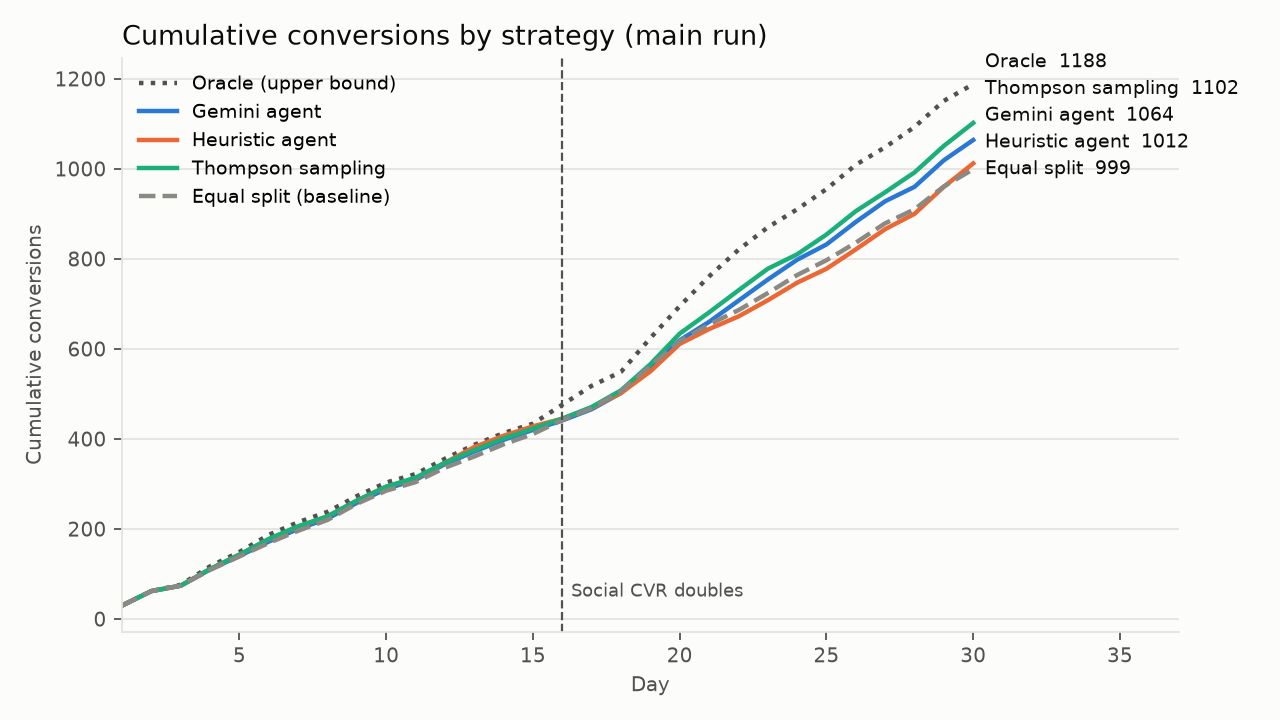

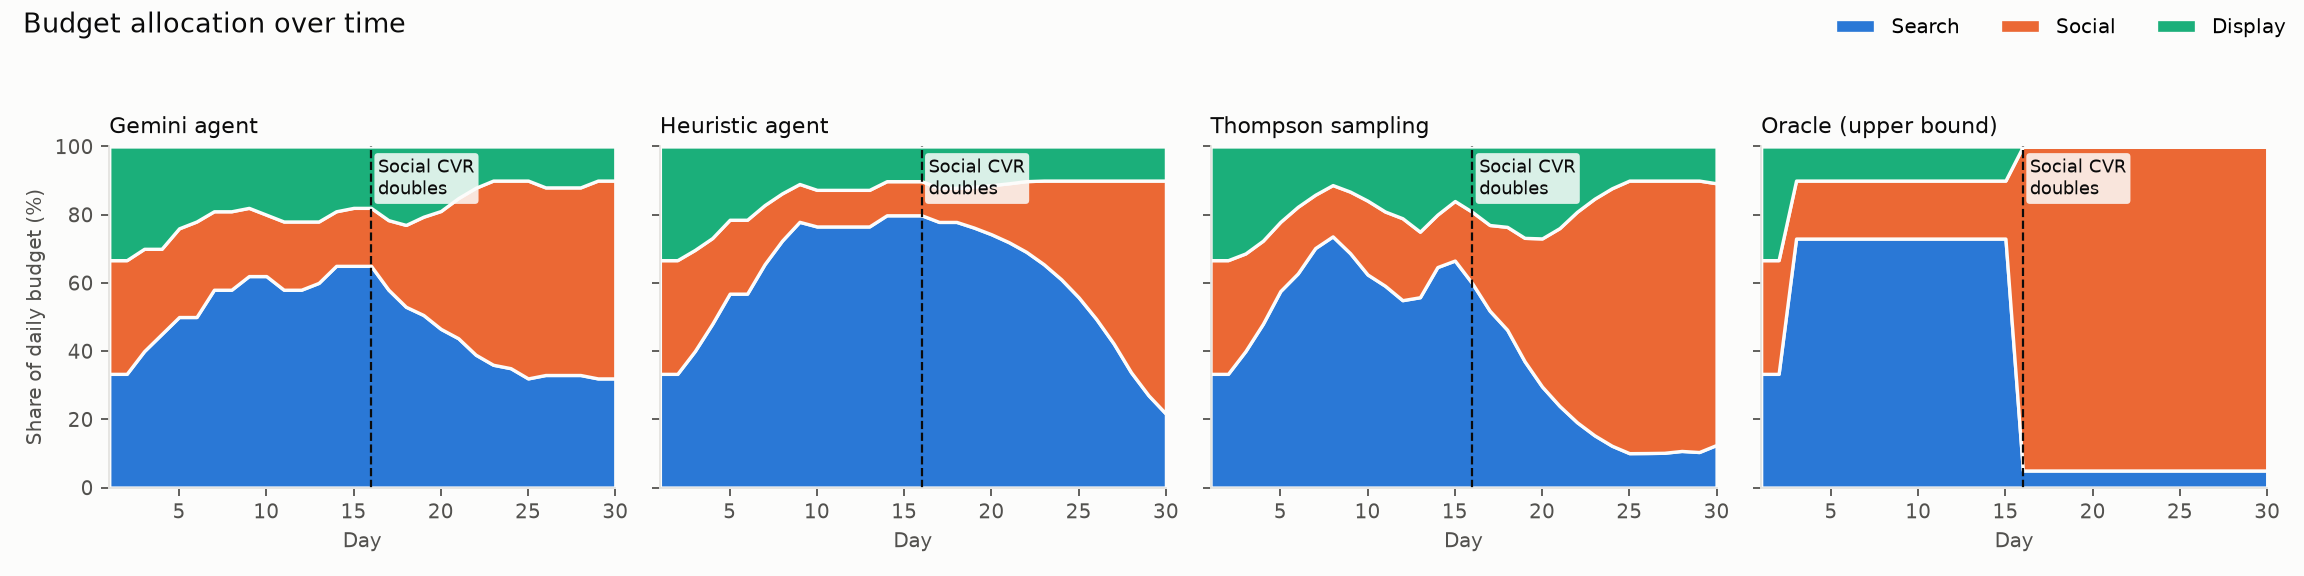

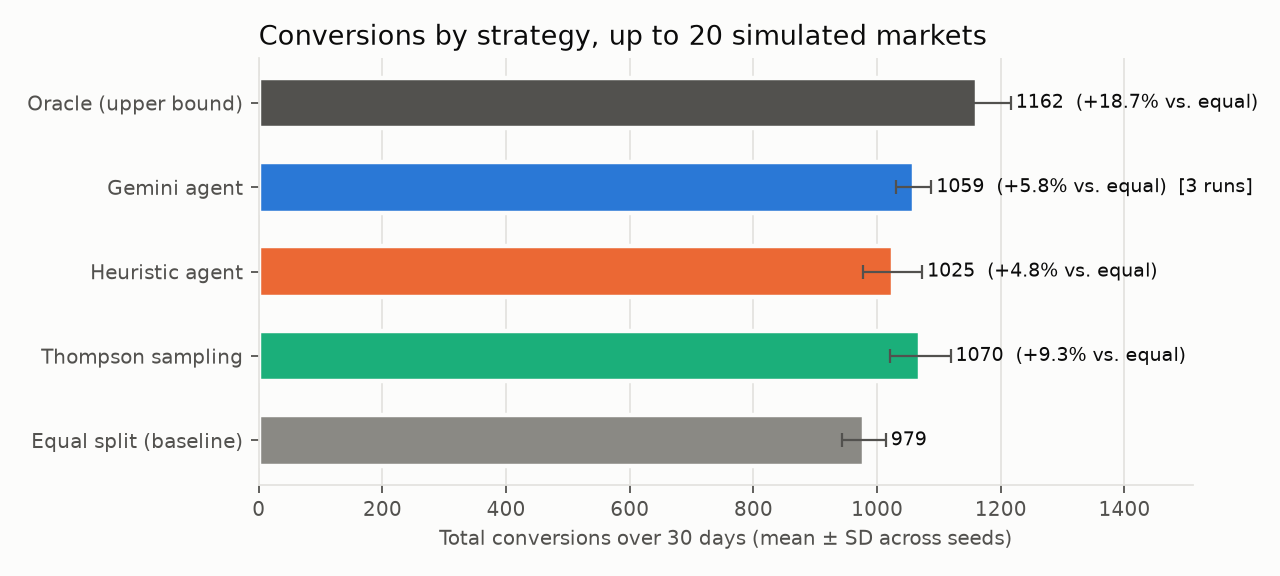

In [10]:
for f in ["cumulative_conversions.png", "allocation_over_time.png", "conversions_by_strategy.png"]:
    display(Image(f"outputs/{f}"))

## Takeaways

- Every learning strategy beats the equal split, mainly by moving money out of Display (the highest CPA).
- On the same 3 markets: Gemini +5.8%, heuristic +4.4%, Thompson sampling +8.0%, oracle +19.0%.
- Gemini kept more budget in Social before day 16 (15-20% vs. the 10% floor), so it moved into Social sooner
  once Social improved. But it stayed cautious and kept about a third of the budget in Search afterwards, which is
  why Thompson sampling still did better.
- The guardrails have a cost: a channel pushed down to the 10% floor can only grow 20% a day, so when Social
  improves on day 16 it takes about a week to move real money there. That is the price of avoiding
  overreaction to noise, and it shows up as regret vs. the oracle.
- The `source` column in `outputs/decisions_log.csv` shows which decisions Gemini made (all 28 in the main run)
  and which fell back to the heuristic.